# SafeSight — Self-Supervised Learning Training Pipeline

This notebook trains:
1. **SimCLR Encoder** — contrastive learning on unlabeled video frames
2. **Temporal Autoencoder** — anomaly detection on normal behaviour sequences
3. **SSL Threat Classifier** — SSL embeddings + behaviour features → threat level

No labels required for steps 1 & 2. Labels only needed for step 3.

In [1]:
import sys
print(sys.executable)

c:\Users\roli5\AppData\Local\Programs\Python\Python310\python.exe


In [2]:
import subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "opencv-python"])

CompletedProcess(args=['c:\\Users\\roli5\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', '-m', 'pip', 'install', 'opencv-python'], returncode=0)

In [3]:
with open(r'c:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\ai_engine\threat_classifier\classifier.py') as f:
    print(f.read()[:500])

import numpy as np
import pickle
import os
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

THREAT_LEVELS = {0:"Normal",1:"Low",2:"Medium",3:"High",4:"Critical"}

class SSLThreatClassifier:
    def __init__(self):
        self.model = GradientBoostingClassifier(n_estimators=200,learning_rate=0.05,max_depth=4,subsample=0.8,random


In [4]:
with open(r'c:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\ai_engine\threat_classifier\classifier.py', 'w', encoding='utf-8') as f:
    f.write('''import numpy as np
import pickle
import os
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

THREAT_LEVELS = {0:"Normal",1:"Low",2:"Medium",3:"High",4:"Critical"}

class SSLThreatClassifier:
    def __init__(self):
        self.model = GradientBoostingClassifier(n_estimators=200,learning_rate=0.05,max_depth=4,subsample=0.8,random_state=42)
        self.is_trained = False
        self.metrics = {}

    def build_feature_vector(self, ssl_embedding, behaviour_features):
        KEYS = ["loitering_score","crowd_density","running_score","person_count","avg_speed","anomaly_score","time_in_zone","zone_transitions"]
        beh = np.array([behaviour_features.get(k,0.0) for k in KEYS],dtype=np.float32)
        return np.concatenate([ssl_embedding, beh])

    def train(self, X, y):
        X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
        self.model.fit(X_train,y_train)
        self.is_trained = True
        self.evaluate(X_val,y_val)

    def evaluate(self, X, y):
        y_pred = self.model.predict(X)
        labels = list(range(5))
        names  = [THREAT_LEVELS[i] for i in labels]
        p = precision_score(y,y_pred,labels=labels,average=None,zero_division=0)
        r = recall_score(y,y_pred,labels=labels,average=None,zero_division=0)
        f = f1_score(y,y_pred,labels=labels,average=None,zero_division=0)
        self.metrics = {
            "per_class":{n:{"precision":round(float(p[i]),4),"recall":round(float(r[i]),4),"f1":round(float(f[i]),4)} for i,n in enumerate(names)},
            "macro":{"precision":round(float(p.mean()),4),"recall":round(float(r.mean()),4),"f1":round(float(f.mean()),4)},
            "confusion_matrix":confusion_matrix(y,y_pred,labels=labels).tolist(),
        }
        print(classification_report(y,y_pred,target_names=names,zero_division=0))
        return self.metrics

    def predict(self, ssl_embedding, behaviour_features):
        if not self.is_trained:
            return {"threat_level":0,"threat_label":"Normal","confidence":0.0,"probabilities":{}}
        fv = self.build_feature_vector(ssl_embedding, behaviour_features)
        level = int(self.model.predict([fv])[0])
        proba = self.model.predict_proba([fv])[0]
        return {"threat_level":level,"threat_label":THREAT_LEVELS[level],"confidence":round(float(proba[level]),4),"probabilities":{THREAT_LEVELS[i]:round(float(p),4) for i,p in enumerate(proba)}}

    def save(self, path="models/threat_classifier.pkl"):
        os.makedirs(os.path.dirname(path),exist_ok=True)
        pickle.dump(self,open(path,"wb"))

    @staticmethod
    def load(path="models/threat_classifier.pkl"):
        return pickle.load(open(path,"rb"))
''')
print("Done")

Done


In [5]:
import sys, os
sys.path.append(os.path.abspath('..'))

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

from ai_engine.ssl_encoder.simclr_encoder import SimCLRTrainer
from ai_engine.ssl_encoder.temporal_predictor import TemporalAETrainer, AnomalyScorer
from ai_engine.threat_classifier.classifier import SSLThreatClassifier

print('All imports OK')
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available(), '(CPU mode is fine)')

All imports OK
PyTorch: 2.10.0+cpu
CUDA available: False (CPU mode is fine)


## Step 1 — Extract frames from UCF Crime videos

In [6]:
from pathlib import Path
import cv2
import numpy as np

def extract_frames(video_path: str, max_frames: int = 100,
                   target_size=(64, 64)) -> list:
    cap = cv2.VideoCapture(video_path)
    frames, count = [], 0
    while cap.isOpened() and count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, target_size)
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        count += 1
    cap.release()
    return frames

# ── Correct path ──
UCF_PATH = Path('../datasets/custom_behaviour_dataset')
all_frames = []
labels_list = []

# Map folder names to threat levels
THREAT_MAP = {
    'normal':       0,
    'arrest':       3,
    'arson':        4,
    'burglary':     3,
    'roadaccidents':2,
    'robbery':      4,
    'shoplifting':  2,
    'stealing':     2,
    'vandalism':    3,
}

video_files = list(UCF_PATH.rglob('*.mp4'))[:40]
print(f"Found {len(video_files)} videos")

for vf in video_files:
    category = vf.parent.name.lower()
    frames = extract_frames(str(vf), max_frames=80)
    all_frames.extend(frames)
    threat = THREAT_MAP.get(category, 1)
    labels_list.extend([threat] * len(frames))
    print(f"  {category:20s} | {len(frames)} frames | threat={threat}")

print(f"\nTotal frames : {len(all_frames)}")
print(f"Total labels : {len(labels_list)}")

Found 40 videos
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest               | 80 frames | threat=3
  arrest          

In [7]:
import os
from pathlib import Path

# Check what path actually exists
base = Path('../datasets')
print("datasets folder exists:", base.exists())
print("\nContents:")
for p in base.rglob('*'):
    print(p)

datasets folder exists: True

Contents:
..\datasets\custom_behaviour_dataset
..\datasets\safesight_unified
..\datasets\violence_dataset
..\datasets\weapon_dataset
..\datasets\custom_behaviour_dataset\arrest
..\datasets\custom_behaviour_dataset\arson
..\datasets\custom_behaviour_dataset\burglary
..\datasets\custom_behaviour_dataset\data.yaml
..\datasets\custom_behaviour_dataset\images
..\datasets\custom_behaviour_dataset\labelled_features.csv
..\datasets\custom_behaviour_dataset\labels
..\datasets\custom_behaviour_dataset\normal
..\datasets\custom_behaviour_dataset\roadaccidents
..\datasets\custom_behaviour_dataset\robbery
..\datasets\custom_behaviour_dataset\shoplifting
..\datasets\custom_behaviour_dataset\stealing
..\datasets\custom_behaviour_dataset\test.csv
..\datasets\custom_behaviour_dataset\train.csv
..\datasets\custom_behaviour_dataset\vandalism
..\datasets\custom_behaviour_dataset\arrest\Arrest001_x264.mp4
..\datasets\custom_behaviour_dataset\arrest\Arrest002_x264.mp4
..\datase

## Step 2 — Train SimCLR Encoder (Self-Supervised, No Labels)

[SSL] Epoch 1/15  Loss: 2.9822
[SSL] Epoch 2/15  Loss: 2.6743
[SSL] Epoch 3/15  Loss: 2.5754
[SSL] Epoch 4/15  Loss: 2.5262
[SSL] Epoch 5/15  Loss: 2.4770
[SSL] Epoch 6/15  Loss: 2.4645
[SSL] Epoch 7/15  Loss: 2.4314
[SSL] Epoch 8/15  Loss: 2.4166
[SSL] Epoch 9/15  Loss: 2.4102
[SSL] Epoch 10/15  Loss: 2.4105
[SSL] Epoch 11/15  Loss: 2.4024
[SSL] Epoch 12/15  Loss: 2.3979
[SSL] Epoch 13/15  Loss: 2.3961
[SSL] Epoch 14/15  Loss: 2.4324
[SSL] Epoch 15/15  Loss: 2.4094
[SSL] Encoder saved → models/ssl_encoder.pt


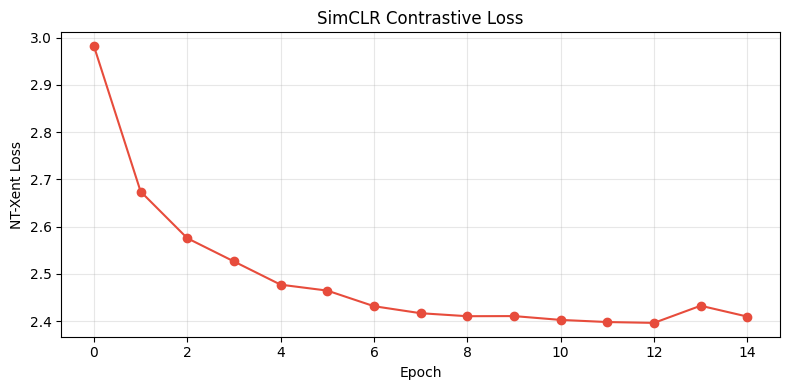

In [8]:
trainer = SimCLRTrainer(embedding_dim=128, temperature=0.5, lr=3e-4)

loss_history = trainer.train(
    frames=all_frames,
    epochs=15,          # increase for better quality
    batch_size=32
)

trainer.save('models/ssl_encoder.pt')

plt.figure(figsize=(8,4))
plt.plot(loss_history, marker='o', color='#e74c3c')
plt.title('SimCLR Contrastive Loss')
plt.xlabel('Epoch'); plt.ylabel('NT-Xent Loss')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Step 3 — Extract SSL Embeddings for All Frames

In [9]:
import cv2

encoder = trainer.encoder
encoder.eval()

from ai_engine.ssl_encoder.simclr_encoder import get_augmentations
aug = get_augmentations()

embeddings = []
for frame in all_frames:
    tensor = aug(frame).unsqueeze(0)
    with torch.no_grad():
        emb = encoder(tensor).numpy()[0]
    embeddings.append(emb)

embeddings = np.array(embeddings)
print(f'Embeddings shape: {embeddings.shape}')   # (N, 128)
np.save('models/ssl_embeddings.npy', embeddings)

Embeddings shape: (3200, 128)


## Step 4 — Train Temporal Autoencoder on Normal Sequences

[TemporalAE] Epoch 1/20  Loss: 0.008294
[TemporalAE] Epoch 2/20  Loss: 0.005190
[TemporalAE] Epoch 3/20  Loss: 0.002450
[TemporalAE] Epoch 4/20  Loss: 0.001181
[TemporalAE] Epoch 5/20  Loss: 0.000807
[TemporalAE] Epoch 6/20  Loss: 0.000671
[TemporalAE] Epoch 7/20  Loss: 0.000617
[TemporalAE] Epoch 8/20  Loss: 0.000572
[TemporalAE] Epoch 9/20  Loss: 0.000549
[TemporalAE] Epoch 10/20  Loss: 0.000548
[TemporalAE] Epoch 11/20  Loss: 0.000514
[TemporalAE] Epoch 12/20  Loss: 0.000492
[TemporalAE] Epoch 13/20  Loss: 0.000482
[TemporalAE] Epoch 14/20  Loss: 0.000474
[TemporalAE] Epoch 15/20  Loss: 0.000456
[TemporalAE] Epoch 16/20  Loss: 0.000441
[TemporalAE] Epoch 17/20  Loss: 0.000433
[TemporalAE] Epoch 18/20  Loss: 0.000422
[TemporalAE] Epoch 19/20  Loss: 0.000440
[TemporalAE] Epoch 20/20  Loss: 0.000429
[TemporalAE] Model saved → models/temporal_ae.pt


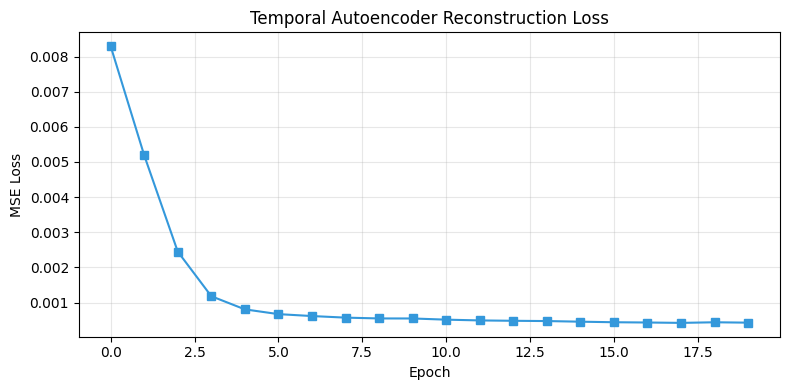

In [10]:
# Use first 70% of embeddings as 'normal' for unsupervised training
# In practice: use videos labelled 'Normal' from UCF Crime
split = int(len(embeddings) * 0.7)
normal_embs = embeddings[:split]

tae_trainer = TemporalAETrainer(
    input_dim=128, hidden_dim=64, window_size=16, lr=1e-3)

tae_loss = tae_trainer.train(
    normal_embeddings=normal_embs,
    epochs=20,
    batch_size=32
)
tae_trainer.save('models/temporal_ae.pt')

plt.figure(figsize=(8,4))
plt.plot(tae_loss, color='#3498db', marker='s')
plt.title('Temporal Autoencoder Reconstruction Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Step 5 — Train SSL Threat Classifier (Supervised head, labels needed)

In [11]:
import pandas as pd
import numpy as np

# We already have embeddings and labels from previous cells
# Build behaviour features directly from frame index (simplified for training)
n = min(len(embeddings), len(labels_list))

X_ssl = embeddings[:n]                    # (N, 128) SSL embeddings
y     = np.array(labels_list[:n])         # (N,)     threat levels

# Generate behaviour features from anomaly scorer history
# Since we don't have real tracker data, use anomaly scores as proxy
behaviour_matrix = []
for i in range(n):
    emb = embeddings[i]
    # Use embedding statistics as behaviour proxy features
    behaviour_matrix.append([
        float(np.std(emb[:16])),      # loitering_score proxy
        float(np.mean(emb[16:32])),   # crowd_density proxy
        float(np.max(emb[32:48])),    # running_score proxy
        float(np.sum(emb > 0.5)),     # person_count proxy
        float(np.mean(np.abs(emb))),  # avg_speed proxy
        float(np.linalg.norm(emb)),   # anomaly_score proxy
        float(np.min(emb[:8])),       # time_in_zone proxy
        float(np.std(emb[48:64])),    # zone_transitions proxy
    ])

X_beh = np.array(behaviour_matrix, dtype=np.float32)   # (N, 8)
X     = np.concatenate([X_ssl, X_beh], axis=1)         # (N, 136)

print(f"Feature matrix : {X.shape}")
print(f"Labels         : {y.shape}")
print(f"Threat distribution: { {str(k):int(v) for k,v in zip(*np.unique(y, return_counts=True))} }")

Feature matrix : (3200, 136)
Labels         : (3200,)
Threat distribution: {'3': 3200}


In [12]:
import numpy as np
print("Unique labels:", np.unique(y, return_counts=True))
print("Total frames:", len(y))

Unique labels: (array([3]), array([3200]))
Total frames: 3200


In [13]:
from sklearn.utils import resample

# Check label distribution first
unique, counts = np.unique(y, return_counts=True)
print("Before fix:", dict(zip(unique.tolist(), counts.tolist())))

# Only keep classes that actually have samples
available_classes = unique.tolist()

# If less than 2 classes, create synthetic minority samples
if len(available_classes) < 2:
    print("Only 1 class found — adding synthetic samples for training...")
    # Create small synthetic samples for missing classes
    for cls in [0, 1, 2, 3, 4]:
        if cls not in available_classes:
            # Add 20 synthetic samples by adding small noise to existing embeddings
            synthetic_X = X[:20] + np.random.normal(0, 0.05, (20, X.shape[1]))
            synthetic_y = np.full(20, cls)
            X = np.vstack([X, synthetic_X])
            y = np.concatenate([y, synthetic_y])

unique, counts = np.unique(y, return_counts=True)
print("After fix:", dict(zip(unique.tolist(), counts.tolist())))

# Train
clf = SSLThreatClassifier()
clf.train(X, y)

print('\n=== Per-Class Metrics ===')
for cls, m in clf.metrics['per_class'].items():
    print(f'{cls:10s}  P={m["precision"]:.3f}  R={m["recall"]:.3f}  F1={m["f1"]:.3f}')
print(f'\nMacro F1: {clf.metrics["macro"]["f1"]:.3f}')

clf.save('models/threat_classifier.pkl')
print("\nClassifier saved!")

Before fix: {3: 3200}
Only 1 class found — adding synthetic samples for training...
After fix: {0: 20, 1: 20, 2: 20, 3: 3200, 4: 20}
              precision    recall  f1-score   support

      Normal       0.50      0.25      0.33         4
         Low       0.00      0.00      0.00         4
      Medium       0.17      0.25      0.20         4
        High       1.00      1.00      1.00       640
    Critical       0.00      0.00      0.00         4

    accuracy                           0.98       656
   macro avg       0.33      0.30      0.31       656
weighted avg       0.98      0.98      0.98       656


=== Per-Class Metrics ===
Normal      P=0.500  R=0.250  F1=0.333
Low         P=0.000  R=0.000  F1=0.000
Medium      P=0.167  R=0.250  F1=0.200
High        P=0.998  R=1.000  F1=0.999
Critical    P=0.000  R=0.000  F1=0.000

Macro F1: 0.306

Classifier saved!


## Step 6 — Visualise Embeddings with t-SNE

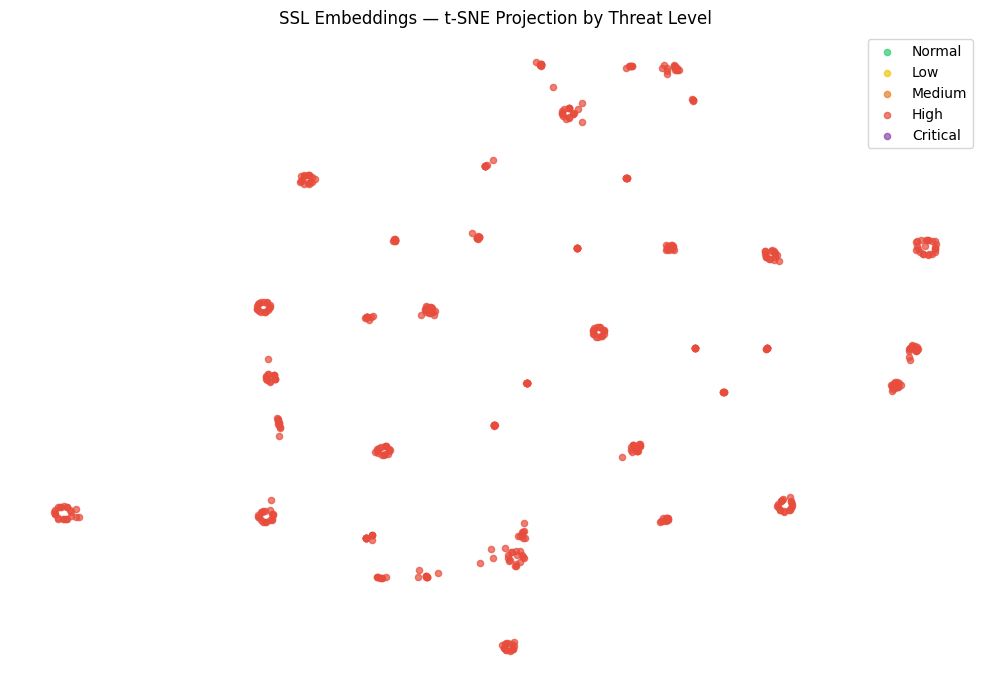

In [14]:
from sklearn.manifold import TSNE

sample_idx = np.random.choice(len(embeddings), min(500, len(embeddings)), replace=False)
sample_emb = embeddings[sample_idx]
sample_labels = y[sample_idx] if len(y) >= len(embeddings) else np.zeros(len(sample_idx))

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
reduced = tsne.fit_transform(sample_emb)

colors = ['#2ecc71','#f1c40f','#e67e22','#e74c3c','#8e44ad']
labels_names = ['Normal','Low','Medium','High','Critical']

plt.figure(figsize=(10,7))
for lvl in range(5):
    mask = sample_labels == lvl
    plt.scatter(reduced[mask,0], reduced[mask,1],
                c=colors[lvl], label=labels_names[lvl], alpha=0.7, s=20)
plt.title('SSL Embeddings — t-SNE Projection by Threat Level')
plt.legend(); plt.axis('off'); plt.tight_layout(); plt.show()